# Ozzy Osbourne songs analysis and evolution using AI
By Alex Balan


 **Recommended read** for this notebook - BERTopic: Neural topic modeling with a class-based TF-IDF procedure by Maarten Grootendorst

 **Reading time: 1.5-2 hours**


## 1. How the corpus was collected (check the GitHub repo)

### 1.1 Scraping

1. Ozzy lyrics were scraped from **DarkLyrics**.
2. The scraped HTML was turned into JSON and initially cleaned.

### 1.2 Knowledge base

3. I collected a **knowledge base** from Wikipedia with all Ozzy albums across
   his career, with the correct release dates.

> *Diary of a Madman* has contradictory information on the exact release date,
> which is left **null** in the KB and represents a perfect example of missing
> information.

### 1.3 RAG pipeline

4. A **RAG** pipeline is built and all songs are embedded, plus the KB album
   cards, with the **BAAI large** model.

   The model has a window of **512 tokens**, which meant every song fit into a
   single chunk and is therefore represented by one vector — the only exception
   being *"Don't Blame Me"*, which exceeded the window.

   The model uses **CLS pooling**: the representation is taken from the `[CLS]`
   token rather than averaged across all tokens. This matters, because mean
   pooling would let frequent tokens dominate the representation — remember
   **Zipf's Law**, and how much of any document is stop-words.

### 1.4 The critic

5. After the embeddings, a **critic** using the small **Qwen 3 4B** model flags
   any songs in the corpus which are not in the KB. This is mainly to avoid
   including songs in the analysis which were not actually written by Ozzy.

> Think about what happens if we include songs from Black Sabbath in an analysis
> of Ozzy's solo career — we don't want that.

The critic is also used for **factuality safeguarding**, to flag any different
song titles, or hallucinated/wrong years for the albums. The years are very
important to have an evolutionary timeline of lyrics.

### 1.5 Final corpus

6. After combining the RAG, the Qwen critic and our KB, the corpus was reduced
   to only original Ozzy tracks from his released albums. The **"Under Cover"**
   album was fully excluded for the reasons mentioned above.

**Final corpus: 131 songs across 13 albums.**


## 2. What this notebook does

To my knowledge, this is the first Ozzy Osbourne songs dataset containing only
original tracks from the studio album versions, with correct release years.

As you will see in this notebook, with a corpus of clean musical text many
things can be done. We will practice and experiment with a range of concepts —
excluding RAG and factual critics, which we have already seen in the corpus
construction process above.

### Methods covered

- **Word embeddings and tokenization** *(again)*
- **Transformer models**
- **Topic modelling** — extract the main topics from lyrics
- **Graph visualisation methods**, bipartite networks
- **Network science metrics**




In [4]:
with open('corpus.txt', encoding='utf-8') as f:
    text = f.read()

In [5]:
import re
import pandas as pd


In [6]:
print(text)

### I Don't Know - Blizzard of Ozz (1980)

People look to me and say
Is the end near, when is the final day?
What's the future of mankind?
How do I know, I got left behind
Everyone goes through changes
Looking to find the truth
Don't look at me for answers
Don't ask me
I don't know
How am I supposed to know
Hidden meanings that will never show
Fools and prophets from the past
Life's a stage and we're all in the cast
You gotta believe in someone
Asking me who is right
Asking me who to follow
Don't ask me
I don't know
I don't know
I don't know
I don't know
Nobody ever told me
I found out for myself
You gotta believe in foolish miracles
It's not how you play the game
It's if you win or lose
You can choose, don't confuse, win or lose
It's up to you
It's up to you
It's up to you
It's up to you
Go, go, go
People look to me and say
Is the end near, when is the final day?
What's the future of mankind?
How do I know, I got left behind, now I'm lost
Everyone goes through changes
Looking to find 

## 3. Preprocessing and embedding

The Python scripts from the repository prepared the corpus, and further
classical NLP pre-processing methods — such as **stemming** or **stop-word
removal** — should *not* be performed here.

> These methods strip away the semantic and syntactic meaning that embedding
> models expect, because were present in the text the models were
> trained on. Removing them degrades the resulting vectors.

We can use the same **BAAI** model to embed the corpus again. This step is
needed for the clustering and for the classical steps of topic modelling that
follow.

In [7]:
pat = re.compile(r'^###\s*(.+?)\s+-\s+(.+?)\s+\((\d{4})\)\s*$', re.M)
matches = list(pat.finditer(text))

rows = []
for i, m in enumerate(matches):
    start = m.end()
    end = matches[i+1].start() if i+1 < len(matches) else len(text)
    rows.append({
        'title': m.group(1).strip(),
        'album': m.group(2).strip(),
        'year': int(m.group(3)),
        'lyrics': text[start:end].strip(),
    })

df = pd.DataFrame(rows)
print(len(df), df.album.nunique())

131 13


In [8]:
#to see how our collumns are organised in the dataframe
df.head()

,title,album,year,lyrics
0,I Don't Know,Blizzard of Ozz,1980,"People look to me and say\nIs the end near, wh..."
1,Crazy Train,Blizzard of Ozz,1980,"All aboard! Hahaha\nCrazy, but that's how it g..."
2,Goodbye To Romance,Blizzard of Ozz,1980,Yesterday has been and gone\nTomorrow will I f...
3,Suicide Solution,Blizzard of Ozz,1980,"Wine is fine, but whiskey's quicker\nSuicide i..."
4,Mr. Crowley,Blizzard of Ozz,1980,"Mr. Crowley, what went on in your head?\nOh, M..."


In [9]:
print(df.head(20))

                               title              album  year  \
0                       I Don't Know    Blizzard of Ozz  1980   
1                        Crazy Train    Blizzard of Ozz  1980   
2                 Goodbye To Romance    Blizzard of Ozz  1980   
3                   Suicide Solution    Blizzard of Ozz  1980   
4                        Mr. Crowley    Blizzard of Ozz  1980   
5                     No Bone Movies    Blizzard of Ozz  1980   
6          Revelation (Mother Earth)    Blizzard of Ozz  1980   
7             Steal Away (The Night)    Blizzard of Ozz  1980   
8   You Lookin' At Me Lookin' At You    Blizzard of Ozz  1980   
9                  Over The Mountain  Diary of a Madman  1981   
10                 Flying High Again  Diary of a Madman  1981   
11        You Can't Kill Rock & Roll  Diary of a Madman  1981   
12                          Believer  Diary of a Madman  1981   
13                      Little Dolls  Diary of a Madman  1981   
14                       

We should expect 13 albums and 131 songs.

In [10]:
import re

def strip_punct(line):
  #we want t ignore punctuation to what we clean
    return re.sub(r'[^a-z0-9 ]', '', line.lower()).strip()

def remove_repeats(lyrics):
    seen = set()
    kept = []
    for line in lyrics.split('\n'):
        clean = strip_punct(line)
        if clean and clean not in seen:
            seen.add(clean)
            kept.append(line.strip())
    return '\n'.join(kept)


df['lyrics_dedup']  = df['lyrics'].apply(remove_repeats)
df['n_words']       = df['lyrics'].str.split().apply(len)
df['n_words_dedup'] = df['lyrics_dedup'].str.split().apply(len)
df['repeat_ratio']  = 1 - df['n_words_dedup'] / df['n_words']

print(len(df), 'songs |', df['album'].nunique(), 'albums')
print('median repeat ratio:', round(df['repeat_ratio'].median(), 2))

131 songs | 13 albums
median repeat ratio: 0.27


In [11]:
album_order = (df.sort_values('year')['album']
                 .drop_duplicates()
                 .tolist())

df['album'] = pd.Categorical(df['album'], categories=album_order, ordered=True)

print(album_order)

['Blizzard of Ozz', 'Diary of a Madman', 'Bark at the Moon', 'The Ultimate Sin', 'No Rest for the Wicked', 'No More Tears', 'Ozzmosis', 'The Ozzman Cometh', 'Down to Earth', 'Black Rain', 'Scream', 'Ordinary Man', 'Patient Number 9']


## 4. Removing verses which keep repeating in a song

As in any musical application, Ozzy usually includes the same verse in the same
song multiple times. When building the final vector for a song, this will bias
the representation towards that repeated verse.

And if we decide later to embed everything by verse, those verses will always
have a similarity of **1** when computing the cosine between their vectors — so
it will create **near-duplicate chunks**.

In [12]:
def remove_repeats(lyrics):
    seen = set()
    kept = []
    for line in lyrics.split('\n'):
        clean = line.strip().lower()
        if clean and clean not in seen:
            seen.add(clean)
            kept.append(line.strip())
    return '\n'.join(kept)

df['lyrics_dedup'] = df['lyrics'].apply(remove_repeats)

In [13]:
df['n_words_dedup'] = df['lyrics_dedup'].str.split().apply(len)
df['repeat_ratio'] = 1 - df['n_words_dedup'] / df['n_words']

print('median repeat ratio:', round(df['repeat_ratio'].median(), 2))
print()
print(df.nlargest(5, 'repeat_ratio')[['title', 'album', 'repeat_ratio']])

#to see how much we removed from the de-duplication of verses

median repeat ratio: 0.26

                       title                   album  repeat_ratio
80                     Alive           Down to Earth      0.562327
41           Fire In The Sky  No Rest for the Wicked      0.529412
129           God Only Knows        Patient Number 9      0.509158
97   Let Me Hear Your Scream                  Scream      0.500000
122        One Of Those Days        Patient Number 9      0.497585


## 5. Embedding the chunks

Now the next step is to embed everything — turning the text into tokens, and
those tokens into vectors. This includes several sub-steps: first
**tokenization**, then the token embeddings, then the contextual pass through
the transformer, and finally **mean pooling** into one vector per chunk.

Do not confuse tokenization with embeddings. Before embedding everything and learning the conext of surrounding words, we need tokens ids.

### Useful links

- [Tokenization vs. embeddings — a good intro](https://www.geeksforgeeks.org/nlp/tokenization-vs-embeddings/)
- [How GenAI understands language — more conceptual](https://www.ascendientlearning.com/blog/how-genai-understands-language)


In [14]:
!pip install -q sentence-transformers

### 5.1 Dealing with uncommon, domain-specific tokens

We will be using a pre-trained embedding model. However, depending on your task,
it might be that specific vocabulary words need to be reconstructed from too
many known tokens. In really specific cases you might want to add such words to
the vocabulary manually and fine-tune the model on your new vocabulary.

### 5.2 Averaging tokens into one vector

MPNet is a Microsoft model from the BERT family, and it uses the same
WordPiece tokenizer. Unlike BGE, the **mean is computed over all token
embeddings** — so we need to chunk our songs properly and avoid trying to
average too many tokens at once *(think about why)*.

The **max sequence length is 384 word pieces**, and anything longer is silently
truncated — so we need to take care with that in our design as well.

> A good idea for avoiding **bias towards common vocabulary in the averaged
> representation** is to chunk songs into verses, and embed one verse at a time.

**Would the embedding model (trained on English simple corpuses) be suited for music lyrics?**

**What about specific domains like law applications, or biochemestry?**

In [15]:
from sentence_transformers import SentenceTransformer
#you can use your different emmbeding model, but while running on the CPU start with something small and fast
#think about the dimension of the vectors (512 collumns was the old standard for BERT emmebedings)
model = SentenceTransformer('all-mpnet-base-v2')

print(model.tokenizer.tokenize("Mr. Crowley rode the crazy train"))
print(model.tokenizer.tokenize("Sabbath bloody sabbath diabolus"))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

['mr', '.', 'crowley', 'rode', 'the', 'crazy', 'train']
['sabbath', 'bloody', 'sabbath', 'dia', '##bol', '##us']


> **NOTE:** `"diablous"` is firstly an **unknown token**, which is being
> reconstructed from known sub-tokens. If those specific sub-tokens were also
> unknown, it would fall back to **character-level reconstruction**.
>
> Do you think this can still produce any **OOV** (out-of-vocabulary) words?

Now let's **chunck our songs per verses (around 5)**, to avoid the possible problems mentioned above. This is an important step in your design.  

In [16]:
def make_chunks(lyrics, n_lines=8):
    lines = [l for l in lyrics.split('\n') if l.strip()]

    blocks = []
    for i in range(0, len(lines), n_lines):
        blocks.append('\n'.join(lines[i:i + n_lines]))

    return blocks


rows = []

for song_id, song in df.iterrows():
    for chunk_no, text in enumerate(make_chunks(song['lyrics_dedup'], n_lines=5)):
        rows.append({
    'song_id':  song_id,
    'title':    song['title'],
    'album':    song['album'],
    'year':     song['year'],
    'chunk_no': chunk_no,
    'text':     text,
})
chunks = pd.DataFrame(rows)


chunks['n_words'] = chunks['text'].str.split().apply(len)
chunks = chunks[chunks['n_words'] >= 15].reset_index(drop=True)

print(len(chunks), 'chunks')
print('chunks per song:', round(len(chunks) / len(df), 1))
print()
print(chunks['n_words'].describe())

660 chunks
chunks per song: 5.0

count    660.000000
mean      29.378788
std        7.355002
min       15.000000
25%       24.000000
50%       29.000000
75%       34.000000
max       60.000000
Name: n_words, dtype: float64


Let's look at one of our chucnks now. Crazy train would be the chunck at position 5.

In [17]:
print(chunks.loc[5, 'title'])
print(chunks.loc[5, 'text'])

Crazy Train
All aboard! Hahaha
Crazy, but that's how it goes
Millions of people living as foes
Maybe. it's not too late
To learn how to love, and forget how to hate


### **Now let's emmbed our entire corpus represented by our 660 chunks**


What would be the dimensions of your vector representations? Think about the dimensionality of the embedding model we are using.
How many rows and how many collumns?

In [18]:
texts = chunks['text'].tolist()
embeddings = model.encode(texts, show_progress_bar=True)

print(embeddings.shape)

Batches:   0%|          | 0/21 [00:00<?, ?it/s]

(660, 768)


In [19]:
#to check that nothing is being truncated due to the maxium tokens window of 384

lengths = [len(model.tokenizer.tokenize(t)) for t in texts]
print('max tokens:', max(lengths))

max tokens: 80


### 5.3 Testing the embeddings

Let's test everything and find the similarity between *Crazy Train* and the
other chunks in the corpus.

> Note that the embeddings are already **unit-normalised**, which makes cosine
> similarity reduce to a simple **dot product** — computationally much cheaper
> than computing norms for every pair.

In [20]:
from sklearn.metrics.pairwise import cosine_similarity

i = 5   # the Crazy Train chunk
sims = cosine_similarity([embeddings[i]], embeddings)[0]

print('QUERY:', chunks.loc[i, 'title'])
print(chunks.loc[i, 'text'])
print('\n--- most similar ---')

for j in sims.argsort()[::-1][1:4]:
    print(f"\n[{sims[j]:.2f}] {chunks.loc[j, 'title']} ({chunks.loc[j, 'album']})")
    print(chunks.loc[j, 'text'])

QUERY: Crazy Train
All aboard! Hahaha
Crazy, but that's how it goes
Millions of people living as foes
Maybe. it's not too late
To learn how to love, and forget how to hate

--- most similar ---

[0.50] Dreamer (Down to Earth)
If only we could all just find serenity
It would be nice if we could live as one
When will all this anger, hate and bigotry ...
Be gone?
Today

[0.44] Love To Hate (Black Rain)
Living in fear
Why do people love to hate
Love to hate
Desensitized and victimized
The action never stops

[0.43] No Escape From Now (Patient Number 9)
Destruction never leads to change
Waiting for the end in vain
Hear them laughing as they go insane
Insane
I'm coming to find you


> **Reading the output.** All three neighbours are about hate, love and
> division, pulled from three different albums spanning **2001, 2007 and 2022**
> — the model found the theme, not the vocabulary.
>
> Nothing from the same song either, which means it isn't just matching on
> shared phrasing.


> The absolute similarities (0.43–0.50) look low, but that is normal for
> sentence transformers on short passages — the scores are compressed into a
> narrow band. Only the **ranking** is meaningful here, not the value.

## 6. Topic modelling

**BERTopic** is not a single algorithm but a pipeline of five swappable steps listed bellow.

It is still one of the best topic modeling methods, especially when there is enough documents to cluster and extract their topics - this works in our favour, as we chuncked songs by verses and produced us much more than simply 131 different songs, encoded in one vector each of them.

| Step | Module | What it does |
|---|---|---|
| 1 | Embedding | Each document becomes a dense vector (we did this already) |
| 2 | Dimensionality reduction (UMAP) | 768 dims → ~5, so density-based clustering works |
| 3 | Clustering (HDBSCAN) | Finds dense groups; sparse points become outliers |
| 4 | Tokenization (CountVectorizer) | Back to bag-of-words, *after* clustering |
| 5 | Weighting (c-TF-IDF) | Scores words per cluster to describe each topic |

**The key idea:** the grouping and the naming happen in two different worlds.

First we group the chunks using their **embeddings** — vectors that capture what
a passage *means*. Two chunks can end up in the same group without sharing a
single word, as you've seen in the previous similiarity to Crazy Train example.

Only afterwards do we look at the actual **words** in each group, to work out
what to call it. Counting words is how we describe a topic, never how we build
it.

This is why removing stop-words in step 4 is safe: by then the groups already
exist and cannot change. We are only deciding which words best describe them,
and "the" and "you" describe nothing - this can use simple TF-IDF methods as used in early information retreival days.

We will build steps 2–5 by hand first, so you can see what each one does. Then
we will run the same pipeline again using the `bertopic` library, which packages
all of it into a few lines.

### Resources

- [BERTopic documentation](https://maartengr.github.io/BERTopic/) — the algorithm page is the best single overview
- Grootendorst, M. (2022). *BERTopic: Neural topic modeling with a class-based TF-IDF procedure.* [arXiv:2203.05794](https://arxiv.org/abs/2203.05794)
- [Understanding UMAP](https://pair-code.github.io/understanding-umap/) — interactive, and the clearest explanation of what the parameters actually do
- McInnes, Healy & Melville (2018). *UMAP: Uniform Manifold Approximation and Projection.* [arXiv:1802.03426](https://arxiv.org/abs/1802.03426)
- [HDBSCAN documentation](https://hdbscan.readthedocs.io/) — see "How HDBSCAN Works"

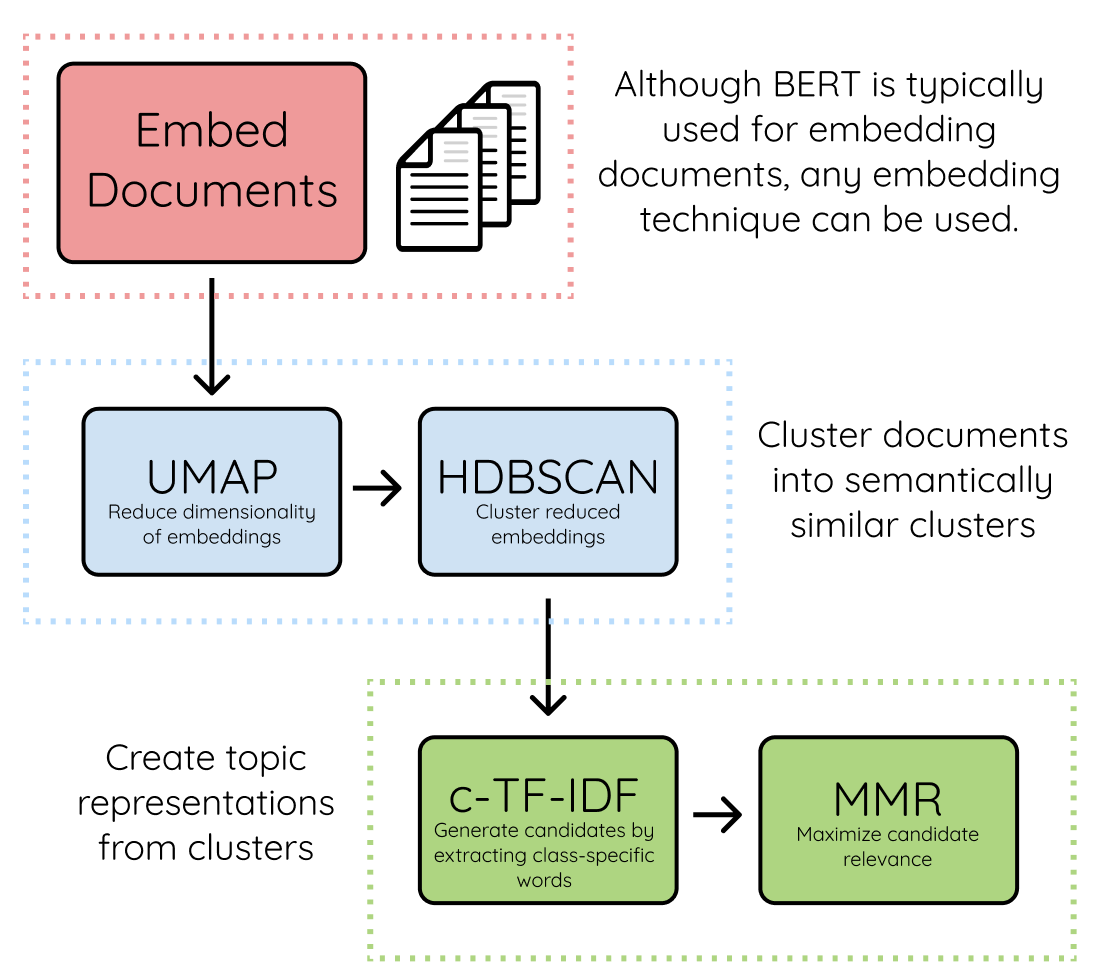

In [21]:
!pip install -q umap-learn

### 6.1.1 Dimensionality reduction with UMAP

Each chunk is now a vector of **768 numbers**. That is far too many dimensions
for clustering to work well.

**Why?** In very high dimensions, every point ends up at roughly the same
distance from every other point. The "near" and "far" that clustering depends
on start to fade. This is known as the **curse of dimensionality** and can apply to many circumstances, like ML predictive algorithms, etc.

**UMAP** fixes this by squeezing the 768 dimensions down to just a few, while
trying to keep chunks that were neighbours still next to each other. It cares
about *local* structure — who is close to whom — more than about exact distances. Close cusing to t-SNE (limited to 2-3 dimensions) , with roots at Maastricht University. On top, UMAP learns the actual mapping and transforms new points, not simply a visualization tool that would nee to re-compute the reduction for all data points again.

| Parameter | What it controls | Our value |
|---|---|---|
| `n_neighbors` | How many neighbours each point looks at. Small = fine detail, large = the big picture | 15 |
| `n_components` | How many dimensions we reduce to | 5 |
| `min_dist` | How tightly points may be packed together. 0 = as tight as possible, best for clustering | 0.0 |
| `metric` | How closeness is measured — cosine, same as our similarity test | `cosine` |
| `random_state` | Fixes the randomness so we get the same result every run | 42 |

> We reduce to **5** dimensions for clustering, not 2. Two dimensions are nice
> to look at but throw away too much information. We'll make a separate 2D
> version just for plotting in the next step.

In [22]:
from umap import UMAP

umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric='cosine',
    random_state=42,
)

reduced = umap_model.fit_transform(embeddings)

print('before:', embeddings.shape)
print('after: ', reduced.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


before: (660, 768)
after:  (660, 5)


Note how our 768 dimensions vectors were squeezed into dimension 5 vectors.

### 6.1.2 Looking at the map

The 5-dimensional version is what we will cluster, but we cannot look at 5
dimensions. So we run UMAP a **second time**, reducing to just 2, only to draw a
picture.

Each dot is one chunk of lyrics. Dots that sit close together have similar
meaning.

We colour the dots by **release year**, from light (early career) to dark (late
career). With 13 albums, giving each its own colour would be unreadable. Year
is an ordered quantity, so a light-to-dark encoding (by color hue) fits it naturally.

> Remember: only "who is close to whom" is meaningful here. The distance
> between two separate groups, and the size of a group, are not.

In [23]:
#run again with 2 dimensions for visualization only
umap_2d = UMAP(
    n_neighbors=15,
    n_components=2,
    min_dist=0.1,
    metric='cosine',
    random_state=42,
)

coords = umap_2d.fit_transform(embeddings)
print(coords.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(660, 2)


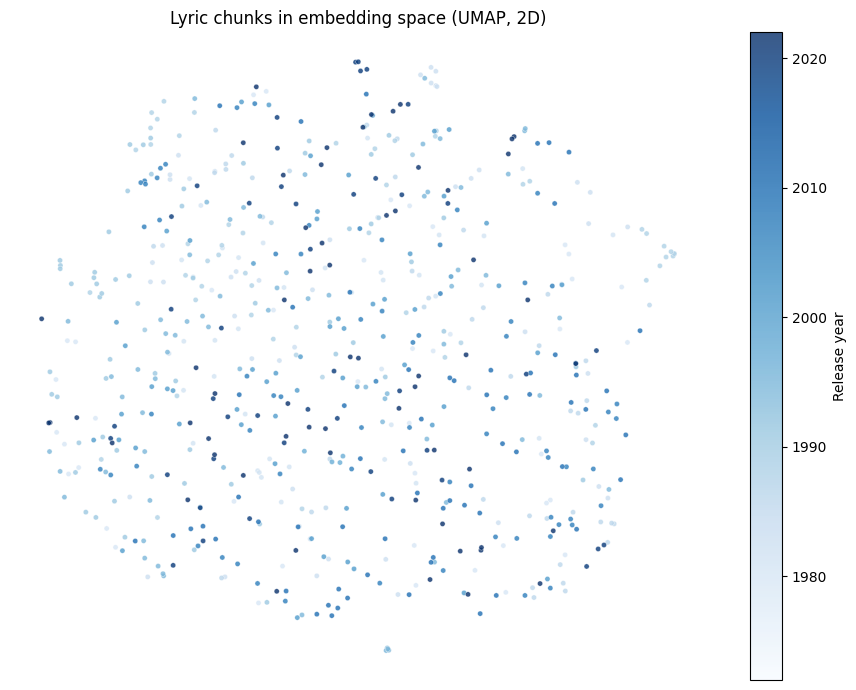

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))

points = ax.scatter(
    coords[:, 0], coords[:, 1],
    c=chunks['year'],
    cmap='Blues',
    #we shift the scale to make 1980 look light, but still visible so not fully white
    vmin=1972,
    s=14,
    alpha=0.8,
    linewidths=0.3,
    edgecolors='white',
)

colorbar = fig.colorbar(points, ax=ax)
colorbar.set_label('Release year')

ax.set_title('Lyric chunks in embedding space (UMAP, 2D)')
ax.set_xticks([])
ax.set_yticks([])
for side in ['top', 'right', 'left', 'bottom']:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

> **What does the map tell us?**
>
> There are no clearly separated groups — the chunks form one continuous cloud and early songs mix with recent ones.
>
> This is a result somewhat expected and think about why it can happen:
>
> - Ozzy's lyrics **blend** from one theme into the next, rather than
>   falling into distinct categories (well, most of his songs include the devil somewhere 🤪 ). That is typical for a single artist
>   within a single genre.
> - The **same themes recur across his whole career**. At this level, there is
>   no obvious "early Ozzy" versus "late Ozzy" region, but looking deeper (and eventually with different methods) we will see that some shape exists still and can describe his transition phases.


In [25]:
!pip install -q hdbscan

### 6.1.3 Clustering with HDBSCAN

Now we look for groups in the 5-dimensional space. We use **HDBSCAN**, which is usually standard for BERTopic, however it can be at any time replaced with a different clustering module.

**The idea** is that HDBSCAN finds these dense regions of points on its own, withot needing to pre-define the number of clusters 'K', as for example K-Means would require. In K-means you could for example compute the Siloutee score to determine an appropiate number of clusters, or look at the WCSS score using the elbow mwthod.


On top, **Not every point has to belong to a cluster.** Points in sparse areas are labelled **-1**, meaning *outlier* or *noise*. K-means for example would force every chunk into some group, even when it fits none of them. So befpore deciding which clustering method you want to proceed with, think about ("do all my points need to belong to a group", "do I know how many clusters I want in advance").


> **Can we score HDBSCAN too?** The silhouette score assumes round and compact
> clusters which is what K-means produces so it tends to penalise
> density-based clusters with irregular shapes and deals poorly with outliers. For density-based methods, the matching measure is
> **DBCV** (Density-Based Clustering Validation), available in the `hdbscan`
> package as `hdbscan.validity.validity_index`.

| Parameter | What it controls | Our value |
|---|---|---|
| `min_cluster_size` | The smallest group allowed to count as a cluster. Bigger means fewer, larger topics | 10 |
| `min_samples` | How strict HDBSCAN is about what counts as "dense". Lower means fewer points marked as outliers | 5 |
| `metric` | How distance is measured.| `euclidean` |

> Given how our map looked, what would you expect?



### Resources: HDBSCAN vs. K-means

**Comparisons**

- [Comparing Python clustering algorithms](https://hdbscan.readthedocs.io/en/latest/comparing_clustering_algorithms.html) — runs K-means, DBSCAN, HDBSCAN and others on the same data and shows where each one fails. The best single resource on this topic to undertand the most important question - when to use what and why.
- [Clustering overview (scikit-learn)](https://scikit-learn.org/stable/modules/clustering.html) — includes the classic figure comparing algorithms on toy datasets.

**How each method works**

- [How HDBSCAN works](https://hdbscan.readthedocs.io/en/latest/how_hdbscan_works.html) — a step-by-step explanation with pictures.
- [Selecting the number of clusters with silhouette analysis (scikit-learn)](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html) — shows silhouette plots, which tell you more than the single score.

**Papers**

- Campello, R. J. G. B., Moulavi, D. & Sander, J. (2013). *Density-based clustering based on hierarchical density estimates.* PAKDD. — the original HDBSCAN paper.
- McInnes, L., Healy, J. & Astels, S. (2017). *hdbscan: Hierarchical density based clustering.* Journal of Open Source Software, 2(11), 205. — the implementation used in this notebook.
- Moulavi, D., Jaskowiak, P. A., Campello, R. J. G. B., Zimek, A. & Sander, J. (2014). *Density-based clustering validation.* SIAM International Conference on Data Mining. — the DBCV score.


In [26]:
import hdbscan

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=10,
    min_samples=5,
    metric='euclidean',
    prediction_data=True,
)


#make sure to cluster the 5D version not the 2D one we used for visualization
labels = clusterer.fit_predict(reduced)

chunks['cluster'] = labels

In [27]:
n_clusters = labels.max() + 1
n_outliers = (labels == -1).sum()

#note that clusters also include the noise cluster which is usually noted as -1 which is not counted here. So if
print('clusters found:', n_clusters)
print(f'outliers: {n_outliers} of {len(labels)} ({n_outliers / len(labels):.0%})')
print()
print(chunks['cluster'].value_counts().sort_index())

clusters found: 9
outliers: 202 of 660 (31%)

cluster
-1    202
 0     14
 1     29
 2     66
 3     24
 4     97
 5     69
 6     95
 7     32
 8     32
Name: count, dtype: int64


> **Result:** HDBSCAN found **9 clusters**, with **202 of 660 chunks (31%)**
> labelled as outliers and noted by cluster id -1 (separate from the 9 clustered classes). The clusters vary a lot in size, from 14 to 97 chunks.
>
> So even though the 2D map looked like one continuous cloud, the 5D space
> does contain denser regions. The next question you need to ask yourself is whether those regions
> *mean* anything.

### 6.1.4 Looking inside the clusters

Before any automatic labelling, we read a few chunks from each cluster. If a
cluster is a real topic (or more), its chunks should share a theme you can name.

HDBSCAN gives every chunk a **probability** saying how firmly it belongs
to its cluster so by looking at the chuncks with the highest probability we can already make an ideea of what we have inside the clusters.

In [28]:
chunks['prob'] = clusterer.probabilities_

for c in range(n_clusters):
    members = chunks[chunks['cluster'] == c]
    top = members.sort_values('prob', ascending=False).head(3)

    print(f' CLUSTER {c}  ({len(members)} chunks) ')
    for _, row in top.iterrows():
        print(f"--- {row['title']} ({row['album']}, {row['year']})")
        print(row['text'])
        print()

 CLUSTER 0  (14 chunks) 
--- Let It Die (Scream, 2010)
Make your heart race
With a death kiss,
I'm a soldier
In a blood war
In the Peace Corps,

--- Shot In The Dark (The Ultimate Sin, 1986)
I wouldn't listen, I learned how to fight
I opened up my mind to treason
But just like the wounded, and when it's too late
They'll remember, they'll surrender
Never a care for the people who hate

--- Let Me Hear Your Scream (Scream, 2010)
Let me hear you scream!
I'm black and bruised, beat up but still I take the blows
'Cause all I need is blood and sweat and skin and bones
I'll take this rage, rattle your cage, nobody said it's easy
It's do or die, only the strong survive, get ready for the last stand!

 CLUSTER 1  (29 chunks) 
--- Miracle Man (No Rest for the Wicked, 1988)
I'm looking for a Miracle Man
That tells me no lies
Who's not in disguise
I don't know where he'll come from
And I don't know where he's been

--- Miracle Man (No Rest for the Wicked, 1988)
To take him higher and higher
Now Ji

> - **Cluster 7:** if we take a look at it, we can see that it tends to group
>   verses about **alcohol addiction**.
> - **Cluster 6:** we cannot really see any pattern, at least for now.
> - **Clusters 1 and 2:** the most typical chunks come from the **same song**.
>   This makes sense, since a song reuses similar wording and themes throughout.
>   But it is not really the desired behaviour: it represents the **trade-off of
>   chunking each song into multiple separate pieces**.

### 6.1.5 Naming the clusters with c-TF-IDF

We have nine groups but no names. HDBSCAN only tells us which chunks belong
together, never why. For that we need to look at the words from each cluster, and we will use a bag of words approach (yes, this can still be effective)

Classic TF-IDF scores a word in one document against how common it is across
all documents. c-TF-IDF changes one thing as we glue all chunks of a
cluster into a single document. So this will give us nine clusters, nine documents. Then we ask :
"is this word rare across clusters?". The rest of the idea stays the same as classic TF-IDF.

$$W_{x,c} = tf_{x,c} \cdot \log\left(1 + \frac{A}{f_x}\right)$$

| | What it is |
| --- | --- |
| $tf_{x,c}$ | Count of word *x* in cluster *c*, divided by total words in *c* |
| $f_x$ | Count of word *x* across all clusters |
| $A$ | Average number of words per cluster |

We divide by cluster length because our clusters run from 14 to 97 chunks and
raw counts would just tell us cluster 4 is big. The $+1$ keeps the weight
positive, so a word present in every cluster is still kept, but ranked low.

How should we deal with stop-words now?



The standard English list was built for prose. *Yeah*, *oh*, *gonna* are
everywhere in a song and carry no topic, so we add our own, but keep in mind that
stop-word lists are always domain-specific.

In [29]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

clustered = chunks[chunks['cluster'] != -1]


docs = (clustered.groupby('cluster')['text']
        .apply(' '.join)
        .sort_index())

vec = CountVectorizer(stop_words='english', min_df=1)
#we will drop stop words from here
X = vec.fit_transform(docs)
words = np.array(vec.get_feature_names_out())

counts = X.toarray()
tf  = counts / counts.sum(axis=1, keepdims=True)   #within-class frequency, normalized already
A   = counts.sum() / counts.shape[0]               #avg words per class
f   = counts.sum(axis=0)                           #word freq across classes
ctfidf = tf * np.log(1 + A / f)

for pos, cluster_id in enumerate(docs.index):
    top = ctfidf[pos].argsort()[::-1][:10]
    size = (clustered.cluster == cluster_id).sum()
    print(f"[{cluster_id}] ({size:>3} chunks)  {', '.join(words[top])}")

[0] ( 14 chunks)  blood, ll, surrender, ready, fight, war, won, fucking, attack, let
[1] ( 29 chunks)  man, miracle, jimmy, sinner, mr, believe, ha, busted, crowley, saw
[2] ( 66 chunks)  love, ll, goodbye, say, yeah, ve, know, just, gonna, time
[3] ( 24 chunks)  away, life, gone, time, tomorrow, day, watching, dream, sun, yesterday
[4] ( 97 chunks)  war, giants, dead, fear, killer, sin, end, final, late, today
[5] ( 69 chunks)  night, hear, head, voices, mind, spiders, inside, darkness, won, evil
[6] ( 95 chunks)  don, know, ll, yeah, like, gonna, rock, truth, goin, just
[7] ( 32 chunks)  don, pain, ooh, drown, alcohol, suicide, demon, way, just, afraid
[8] ( 32 chunks)  run, running, trap, tell, tonight, right, door, tired, hold, carved



> **NOTE:** cluster 8 returns both `run` and `running`. We treat them as 2 different topics now, think about how could we solve this. Next, also treat about what trade-offs this will introduce.


Looking at each cluster topics we can see for example that cluster 1 gets assgined words within the same song mostly (Miracle Men).

Cluster 6 seems to be mostly noise, but cluster 7 for example talks about pain, suicide or alchool - which all combine with addiction.  

Let's define some vocabulary spcific stop-words to try get rid of the noise like "let, like, ll, don, etc" and then check again.

This shows that depending on your domain, we need to properly deal with our stop-words vocabulary, and eventually needing to define new domain specific common words.


In [30]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
docs = (clustered.assign(text=clustered.text.str.replace("'", "", regex=False))
        .groupby('cluster')['text'].apply(' '.join).sort_index())

LYRIC_STOPS = ['yeah','oh','ooh','hey','na','la','ha','haha','gonna','wanna',
               'gotta','dont','wont','aint','cant','im','youre','ive','ill',
               'goin','cos','cause','know','like','just','got','come','let',
               'say','tell','way','time','thing','things']
stops = list(ENGLISH_STOP_WORDS.union(LYRIC_STOPS))

In [31]:
vec = CountVectorizer(stop_words=stops, min_df=1)
X = vec.fit_transform(docs)
words = np.array(vec.get_feature_names_out())

counts = X.toarray()
tf  = counts / counts.sum(axis=1, keepdims=True)
A   = counts.sum() / counts.shape[0]
f   = counts.sum(axis=0)
ctfidf = tf * np.log(1 + A / f)

for pos, cluster_id in enumerate(docs.index):
    top = ctfidf[pos].argsort()[::-1][:10]
    size = (clustered.cluster == cluster_id).sum()
    print(f"[{cluster_id}] ({size:>3} chunks)  {', '.join(words[top])}")

[0] ( 14 chunks)  blood, surrender, fight, ready, war, attack, fucking, lose, strong, stand
[1] ( 29 chunks)  man, miracle, jimmy, hes, mr, sinner, believe, busted, crowley, higher
[2] ( 66 chunks)  love, goodbye, tonight, eyes, little, seen, lonely, tomorrow, close, heart
[3] ( 24 chunks)  away, life, gone, tomorrow, day, watching, dream, sun, yesterday, fading
[4] ( 97 chunks)  war, giants, dead, killer, fear, sin, end, final, late, today
[5] ( 69 chunks)  night, head, hear, hes, spiders, theres, voices, mind, inside, darkness
[6] ( 95 chunks)  rock, truth, rules, youll, crazy, roll, baby, want, mind, change
[7] ( 32 chunks)  pain, drown, alcohol, theres, suicide, demon, afraid, gettin, addicted, die
[8] ( 32 chunks)  run, running, trap, tonight, right, door, tired, hold, pieces, carved


OK, the c-TF-IDF keywords describe each cluster, but they are not yet a label so the next step is to turn ten words into one name.

With 9 clusters this is a job for a human and quite easy. However, we can also classiify those 10 words per each cluster into a final cluster label by using an **encoder model**, or simply a **modern general-knowledge decoder**.

We name them manually here, and keep the keywords next to each name so the
reader can disagree with us.

In [32]:
TOPIC_NAMES = {
    0: 'war / defiance',
    1: 'preachers & religion ',
    2: 'love & goodbyes',
    3: 'time passing',
    4: 'death & apocalypse',
    5: 'voices & madness',
    6: 'Craziness & rockstar vibe',  #you can see why "rock n roll rules, baby etc"
    7: 'addiction',
    8: 'escape / running',
}

clustered = chunks[chunks.cluster != -1]

share = pd.crosstab(clustered.album, clustered.cluster, normalize='index')
share.columns = [TOPIC_NAMES.get(c, c) for c in share.columns]

print(share.round(2).to_string())

                        war / defiance  preachers & religion   love & goodbyes  time passing  death & apocalypse  voices & madness  Craziness & rockstar vibe  addiction  escape / running
album                                                                                                                                                                                     
Bark at the Moon                  0.05                   0.11             0.08          0.03                0.13              0.29                       0.29       0.00              0.03
Black Rain                        0.00                   0.06             0.14          0.04                0.37              0.04                       0.16       0.08              0.10
Blizzard of Ozz                   0.03                   0.15             0.24          0.06                0.21              0.09                       0.09       0.09              0.03
Diary of a Madman                 0.00                   0.05    

**Looking at the topics for each album**


One of the main goals (and expected results) of this entire analysis (besides the educative reasons) is to see how the late career of Ozzy changed. By looking at his last album, we can clearly notice the theme changed from religious or drugs and alchool to disease, madness, end and physical inability.


Let's plot everything conisdering Ozzy's timeline. We will use generatie AI to create te plot.

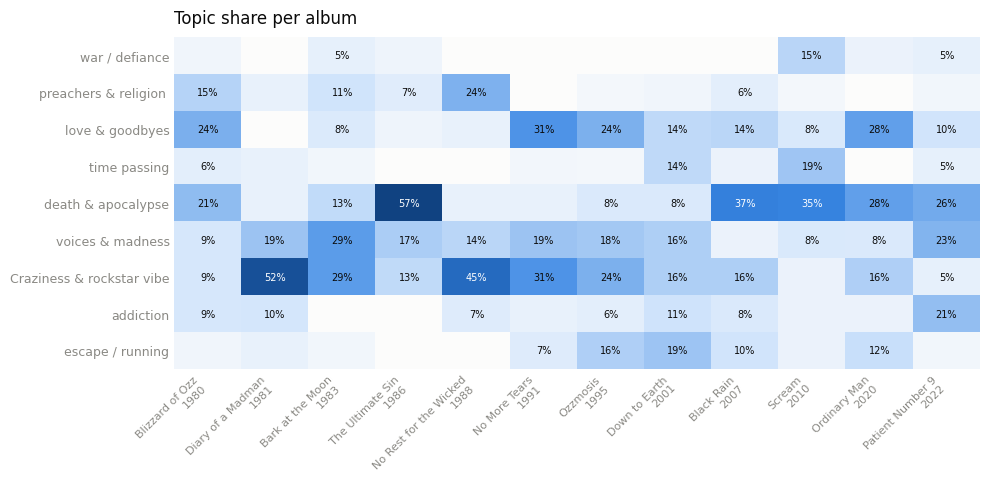

In [38]:

from matplotlib.colors import LinearSegmentedColormap

INK, MUTED = '#0b0b0b', '#8a8984'
BLUES = LinearSegmentedColormap.from_list(
    'seq_blue', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#104281'])

# albums in release order, compilation removed if still present
share_t = share.drop(index='The Ozzman Cometh', errors='ignore')
years = (clustered.groupby('album', observed=True)['year'].first()
         .reindex(share_t.index).dropna().astype(int).sort_values())
share_t = share_t.loc[years.index]
topic_names = list(share_t.columns)
vmax = share_t.values.max()

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(share_t.values.T, cmap=BLUES, aspect='auto', vmin=0, vmax=vmax)

ax.set_xticks(range(len(share_t)), [f'{a}\n{y}' for a, y in zip(share_t.index, years)],
              fontsize=8, rotation=45, ha='right')
ax.set_yticks(range(len(topic_names)), topic_names, fontsize=9)
ax.tick_params(colors=MUTED, length=0)
for s in ax.spines.values():
    s.set_visible(False)

for i in range(share_t.shape[0]):
    for j in range(share_t.shape[1]):
        v = share_t.values[i, j]
        if v >= 0.05:
            ax.text(i, j, f'{v:.0%}', ha='center', va='center', fontsize=7,
                    color='white' if v > vmax * 0.55 else INK)

ax.set_title('Topic share per album', loc='left', fontsize=12, color=INK, pad=10)
plt.tight_layout()
plt.show()

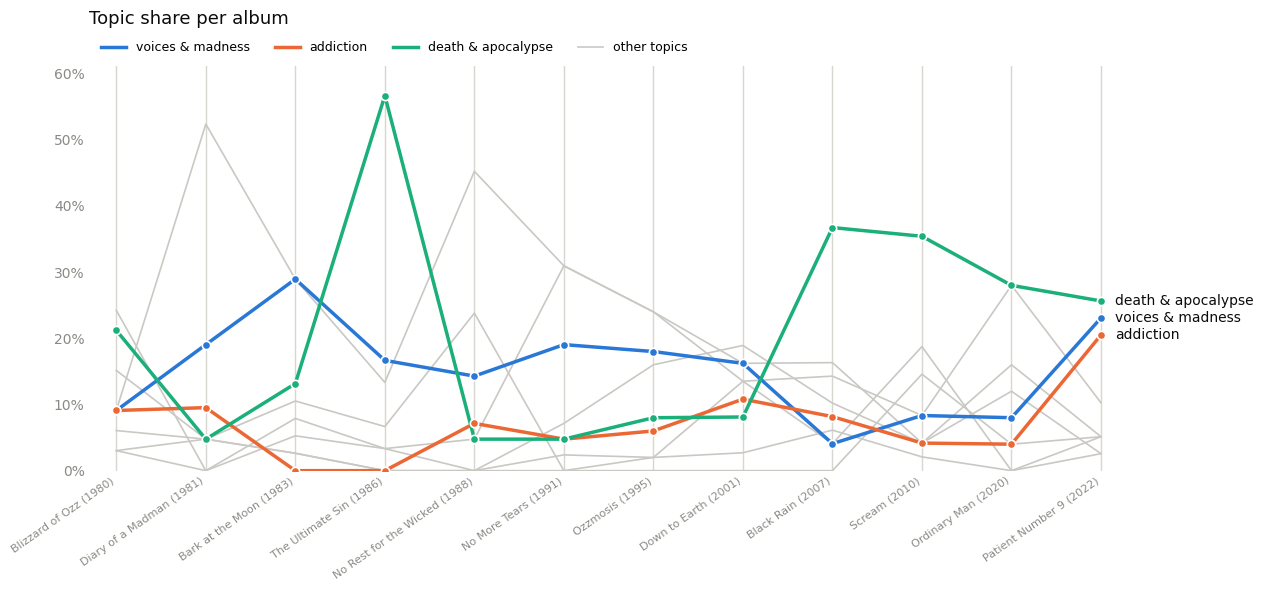

In [39]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

INK, MUTED, AXIS, GREY = '#0b0b0b', '#8a8984', '#d7d6d1', '#c9c8c3'
HIGHLIGHT = {                      # rename to match your TOPIC_NAMES
    'voices & madness':   '#2a78d6',
    'addiction':          '#eb6834',
    'death & apocalypse': '#1baf7a',
}

# albums left to right in release order, compilation removed
share_t = share.drop(index='The Ozzman Cometh', errors='ignore')
years = (clustered.groupby('album', observed=True)['year'].first()
         .reindex(share_t.index).dropna().astype(int).sort_values())
share_t = share_t.loc[years.index]

x = np.arange(len(share_t))
fig, ax = plt.subplots(figsize=(13, 6))

for xi in x:                                   # one vertical axis per album
    ax.axvline(xi, color=AXIS, lw=1, zorder=0)

for topic in share_t.columns:                  # context topics, underneath
    if topic not in HIGHLIGHT:
        ax.plot(x, share_t[topic], color=GREY, lw=1.2, zorder=1)

for topic, color in HIGHLIGHT.items():         # the argument, on top
    y = share_t[topic].values
    ax.plot(x, y, color=color, lw=2.5, zorder=3)
    ax.scatter(x, y, s=36, color=color, edgecolor='white', lw=1.2, zorder=4)
    ax.annotate(topic, (x[-1], y[-1]), xytext=(10, 0),
                textcoords='offset points', va='center', fontsize=10, color=INK)

ax.set_xticks(x, [f'{a} ({y})' for a, y in zip(share_t.index, years)],
              rotation=35, ha='right', fontsize=8)
ax.set_xlim(-0.3, x[-1] + 1.8)                 # room for the end labels
ax.set_ylim(0, share_t.values.max() * 1.08)
ax.yaxis.set_major_formatter(lambda v, p: f'{v:.0%}')
ax.tick_params(colors=MUTED, length=0)
for s in ax.spines.values():
    s.set_visible(False)

handles = [Line2D([], [], color=c, lw=2.5, label=t) for t, c in HIGHLIGHT.items()]
handles.append(Line2D([], [], color=GREY, lw=1.2, label='other topics'))
ax.legend(handles=handles, frameon=False, fontsize=9, ncol=4,
          loc='lower left', bbox_to_anchor=(0, 1.0))
ax.set_title('Topic share per album', loc='left', fontsize=13, color=INK, pad=30)

plt.tight_layout()
plt.show()

## 7. Conclusions

### What did we cover:
On the repository, the full-steps of data scraping, cleaning and the LLM pipeline with RAG and a critic to verify factual information about the albums is availalble. Then, in this notebook we pass step-by-step over different NLP concepts, starting from **tokenization**, **chunking** and **word representations**. Then, we cover in detail each step of BERTopic in the context of our OZZY OSBOURNE analysis.

### What we found:

- **Madness and voices and insanity.** The topic is strong through the
  80s, nearly disappears around his mid career, and comes back on *Patient Number 9* , as expected.
- **Addiction peaks at the very end of his career.** *Patient Number 9* has the highest share of "addiction", which we would expect in his early solo career. This represents a clear example when semantic word representations and **unsupervised** learning can be used to idenitfy pattern we would otherwise not see.
- **Love and goodbyes appears in the middle years**, maybe representing an phase in his life, when family, marriage ("Sharooonnnnn") became to be important for Ozzy.
- **Death, in The Cold War, and above**. First, we see this topic peaking on the Ultimate SIN, which half of the album covers themes from The Cold War, like "Killer of Giants" talking about nuclear power, or "Never" about being born to die - this represents a form of agressive death, following mankind actions. The second and probably the most interesting finding is our second interpretation of death, appearing often in his




## 8. The same pipeline with the BERTopic library

Everything we built by hand in section 6 is packaged in the `bertopic` library.
We pass it the exact same components:

- our embeddings
- our UMAP
- our HDBSCAN
- our stop-words

So any difference in the result comes from the library, not from a different
setup.

### Exercise

Using the BERTopic library, try to reproduce everything we did so far. Pay
attention to use the **exact same** number of dimensions, `min_cluster_size`,
etc.

At the end, note what you observe:

1. Is the library producing the same number of clusters?
2. What happens with the tokens from the unassigned `-1` cluster?
3. Are the words within each cluster the same, or at least similar?